# Plot the MW population per formation channel


## imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
from scipy.stats import gaussian_kde
from posydon.utils.common_functions import convert_metallicity_to_string
from posydon.popsyn.distributions import PowerLawPeriod

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import load_metallicity, load_galactic_observations
from wr_population.classification import (classify_WR, make_binary_mask,
                                          formation_channel_masks, CHANNEL_COLOURS)
from wr_population.plotting import METALLICITY_COLOURS, plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))
COLORS = METALLICITY_COLOURS
from posydon.popsyn.synthetic_population import Population
from wr_population.paths import population_file

from wr_population.plotting import use_posydon_style
use_posydon_style()


## Load POSYDON data

In [2]:
metallicity = 1.0
d = load_metallicity(metallicity)

In [3]:
# Extract final arrays
time_array           = d['time']
weight_array         = d['weight']
model_weight_array   = d['model_weight']
state_array          = d['state']
key_array            = d['key']
star_array           = d['star']
period_array         = d['period']
separation_array     = d['separation']
Teff_array           = d['Teff']
L_array              = d['L']
optical_depth_array  = d['optical_depth']
surface_H_array      = d['surface_H']
surface_He_array     = d['surface_He']
mass_array           = d['mass']
mass_companion_array = d['mass_companion']
radius_array         = d['radius']
Mdot_array           = d['Mdot']
companion_array      = d['companion_state']


In [4]:
WNL, WNE, WC = classify_WR(d)

In [5]:
binary_mask = make_binary_mask(d)

In [6]:
w = weight_array * model_weight_array
WNL_fraction = np.sum(w[binary_mask & WNL])/np.sum(w[binary_mask & (WNL | WNE | WC)])
WNE_fraction = np.sum(w[binary_mask & WNE])/np.sum(w[binary_mask & (WNL | WNE | WC)])
WC_fraction = np.sum(w[binary_mask & WC])/np.sum(w[binary_mask & (WNL | WNE | WC)])
print(f"WNL (H-poor): {WNL_fraction*100:.0f}%")
print(f"WNE (H-free): {WNE_fraction*100:.0f}%")
print(f"WC: {WC_fraction*100:.0f}%")

WNL (H-poor): 14%
WNE (H-free): 58%
WC: 28%


## load observations

In [7]:
obs_df = load_galactic_observations()

In [8]:
obs_df.columns

Index(['System Name', 'evol_type_1', 'evol_type_2', 'obs_type_1', 'obs_type_2',
       'system_class', 'Detection Method', 'Reference', 'Notes',
       'Period_err_lo', 'Period', 'Period_err_hi', 'Eccentricity_err_lo',
       'Eccentricity', 'Eccentricity_err_hi', 'M1_err_lo', 'M1', 'M1_err_hi',
       'M2_err_lo', 'M2', 'M2_err_hi', 'Mass Function_err_lo', 'Mass Function',
       'Mass Function_err_hi', 'M1_sin3i_err_lo', 'M1_sin3i',
       'M1_sin3i_err_hi', 'M2_sin3i_err_lo', 'M2_sin3i', 'M2_sin3i_err_hi',
       'RA_err_lo', 'RA', 'RA_err_hi', 'Dec_err_lo', 'Dec', 'Dec_err_hi'],
      dtype='object')

In [9]:
mask = obs_df['Period'] > 10**2.5
obs_df[['Eccentricity', 'Period']]


,Eccentricity,Period
WR_name,,
WR 9,0.0000,14.305000
WR 11,0.3340,78.530000
WR 19,0.8000,3689.000000
WR 21,0.0400,8.254600
WR 29,0.0000,3.164150
WR 30,NaN,18.820000
WR 30a,0.1500,4.620000
WR 31,0.0000,4.830657
WR 35a,0.0000,41.898000


In [10]:
obs_df.loc[~mask, 'Eccentricity']


WR_name
WR 9       0.0000
WR 11      0.3340
WR 21      0.0400
WR 29      0.0000
WR 30         NaN
WR 30a     0.1500
WR 31      0.0000
WR 35a     0.0000
WR 42      0.0000
WR 47      0.0000
WR 48      0.0000
WR 62a     0.0000
WR 68a     0.0000
WR 79         NaN
WR 97      0.0000
WR 104     0.0000
WR 113     0.0000
WR 127     0.0000
WR 133     0.3558
WR 139     0.0000
WR 145a    0.0000
WR 151     0.0000
WR 155     0.0100
Name: Eccentricity, dtype: float64

In [11]:
LOG_P_MIN, LOG_P_MAX = -1, 6  # shared x-range in log10(P)
OBS_N_BINS = 50             # number of bins for the observations PMF

def plot_observations(obs_df, ax, **kwargs):
    """Observed MW period distribution; the density is scaled by 0.5 for the comparison."""
    plot_period_histogram(ax, obs_df['Period'].dropna().astype(float), n_bins=OBS_N_BINS,
                          log_p_range=(LOG_P_MIN, LOG_P_MAX), scale=0.5,
                          label='Observations', **kwargs)

In [12]:
# full population, used by the investigation cells at the end
pop = Population(str(population_file(metallicity)))

channel_masks = formation_channel_masks(d, metallicity)

# Sana+12 period distribution

WNL: 0.13651619101800175


Stable (S1): 0.491


Stable (S2): 0.217
Unstable (S1): 0.009
Unstable (S2): 0.000


No MT (S1): 0.103


No MT (S2): 0.135
Reverse Stable (S1): 0.045


...

No MT (S2): 0.070
Reverse Stable (S1): 0.028


WC: 0.2819918623178412
Stable (S1): 0.315
Stable (S2): 0.084


Unstable (S1): 0.011
Unstable (S2): 0.040


No MT (S1): 0.359


No MT (S2): 0.174
Reverse Stable (S1): 0.018


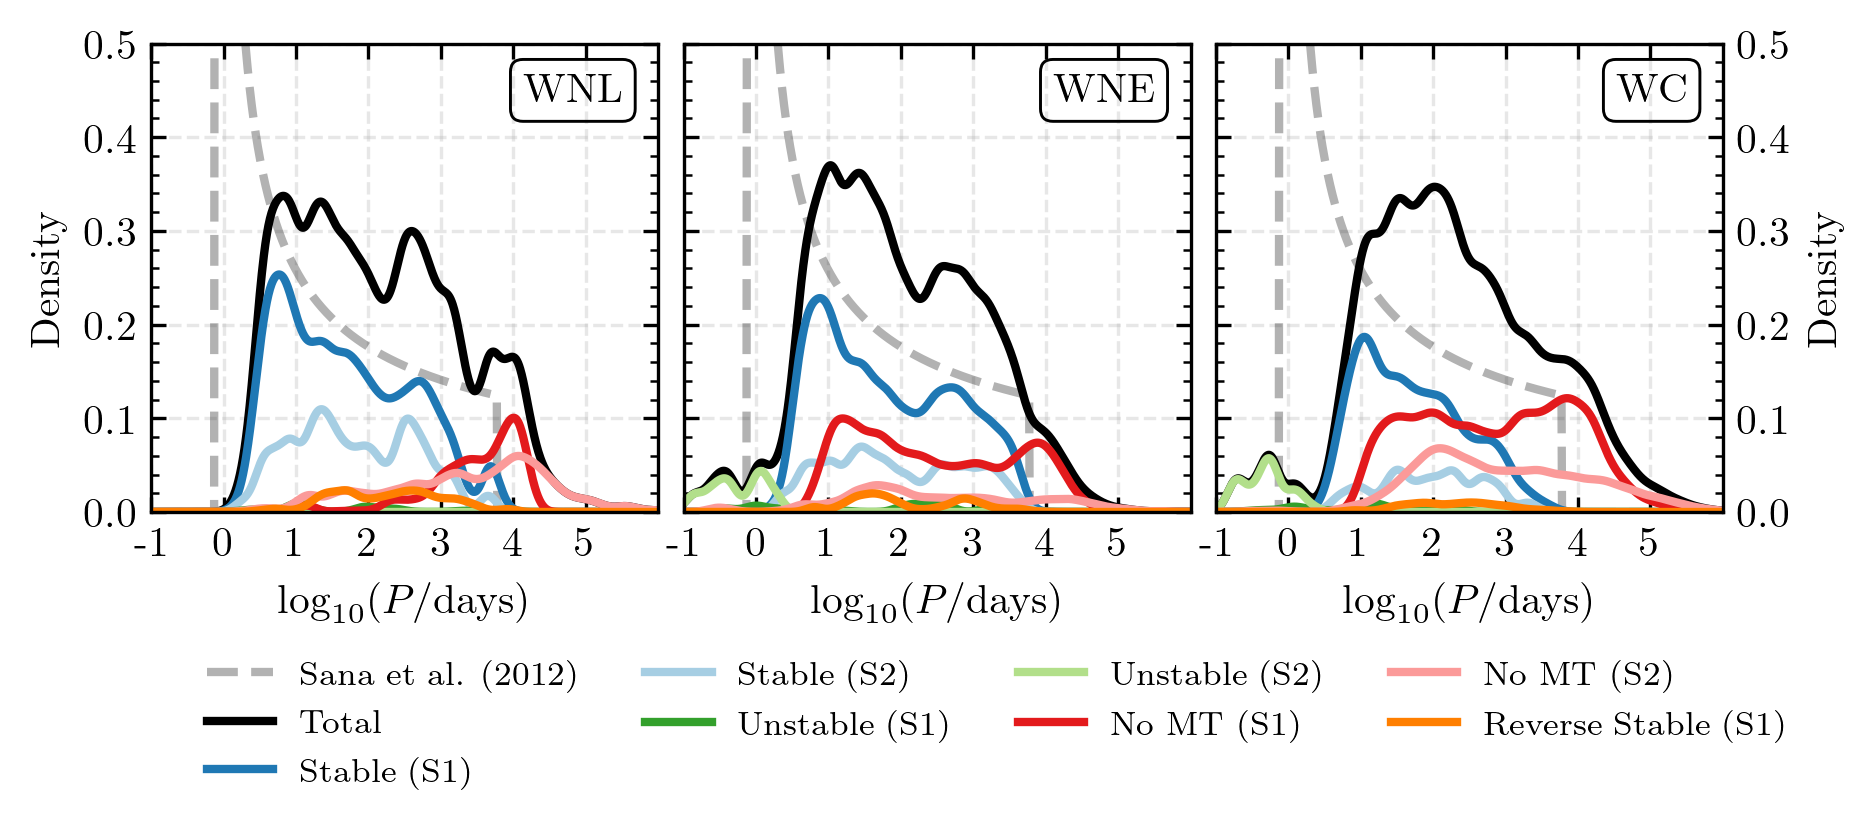

In [13]:
from posydon.popsyn.distributions import Sana12Period

fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

x_eval = np.linspace(-1, 6, 1000)
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)
weights = np.where(np.isclose(model_weight_array,0.0), 0, weight_array)

mask = binary_mask

MT_interactions = channel_masks


colours = CHANNEL_COLOURS


# Setup Sana+12 distribution
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
for ax in axes:
    ax.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')





# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & WNL]), weights=weights[mask & WNL], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & WNL].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNL & mt_mask]), weights=weights[mask & WNL & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNL & mt_mask]) / np.sum(weights[mask & WNL])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Plot WNE
kde = gaussian_kde(np.log10(period_array[mask & WNE]), weights=weights[mask & WNE], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WNE KDEs
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WNE:", weights[mask & WNE].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNE & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNE & mt_mask]), weights=weights[mask & WNE & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNE & mt_mask]) / np.sum(weights[mask & WNE])
    print(f"{label}: {fraction:.3f}")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# plot WC
kde = gaussian_kde(np.log10(period_array[mask & WC]), weights=weights[mask & WC], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WC KDEs
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WC:", weights[mask & WC].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WC & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WC & mt_mask]), weights=weights[mask & WC & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WC & mt_mask]) / np.sum(weights[mask & WC])
    print(f"{label}: {fraction:.3f}")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout

for ax in axes:
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.5)
    ax.grid(True, which='major', ls='--', alpha=0.3)
    

axes[0].set_ylabel('Density')
axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

axes[1].set_yticklabels([])
# move ytick label to right side for right plot
axes[-1].set_ylabel('Density')
axes[-1].yaxis.set_label_position("right")
axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

plt.subplots_adjust(wspace=0.05)

figure_paths = str(EXTRA_FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/MW_subtype_period_distributions_MT_Sana+12.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_subtype_period_distributions_MT_Sana+12.png', bbox_inches='tight', dpi=300)
plt.show()

In [14]:
weights = np.where(np.isclose(model_weight_array,0.0), weight_array, 0)

(16336097,)
(16336097,)


WNL: 1.0


Stable (S1): 0.418


Stable (S2): 0.145


Unstable (S1): 0.014


Unstable (S2): 0.034


No MT (S1): 0.254


No MT (S2): 0.108
Reverse Stable (S1): 0.027


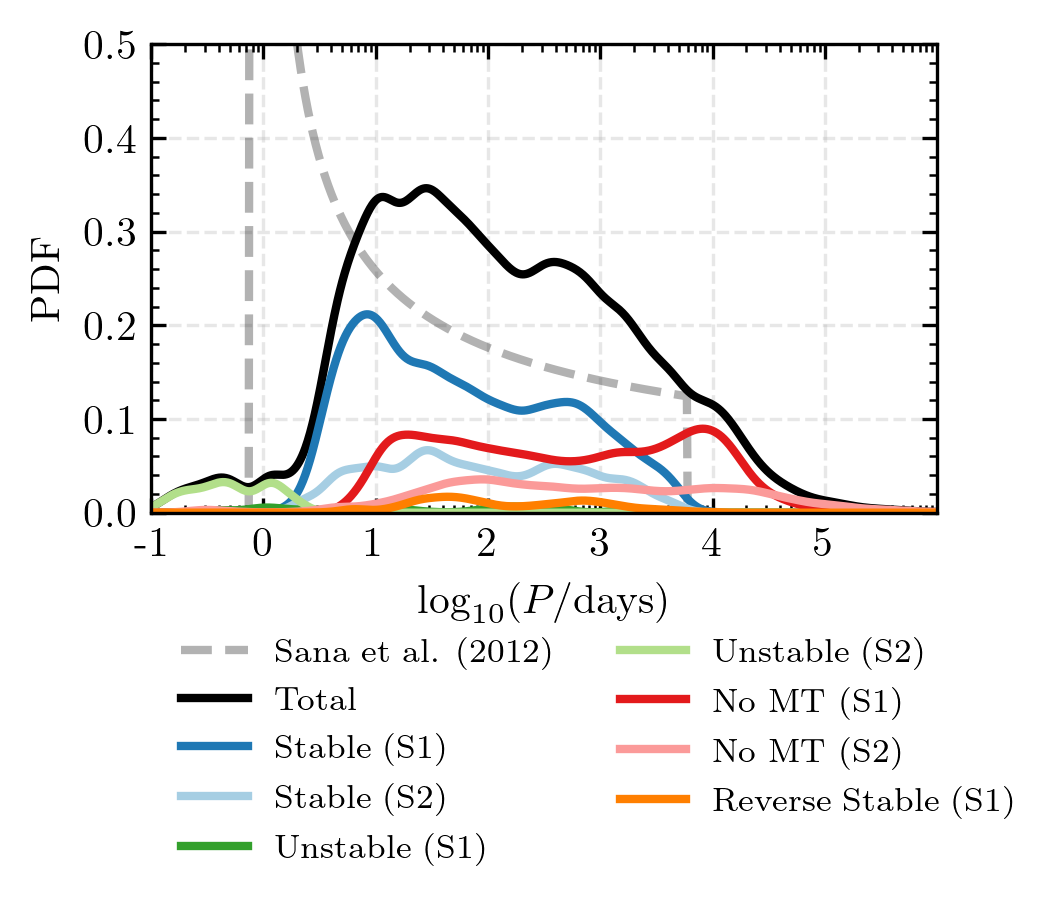

In [15]:
from posydon.popsyn.distributions import Sana12Period

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

x_eval = np.linspace(-1, 6, 1000)
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)
weights = np.where(np.isclose(model_weight_array,0.0), 0, weight_array)

mask = binary_mask

MT_interactions = channel_masks


colours = CHANNEL_COLOURS


# Setup Sana+12 distribution
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
ax.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')



print(period_array[mask].shape)
print(weights[mask].shape)

# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
ax.plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Housekeeping for layout

ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 1e6)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.5)
ax.grid(True, which='major', ls='--', alpha=0.3)
    
ax.set_ylabel('PDF')

# axes[0].set_ylabel('Density')
# axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

# axes[1].set_yticklabels([])
# # move ytick label to right side for right plot
# axes[-1].set_ylabel('Density')
# axes[-1].yaxis.set_label_position("right")
# axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

# axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
# axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
# axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

# plt.subplots_adjust(wspace=0.05)
ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_paths = str(EXTRA_FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions_MT_Sana+12.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions_MT_Sana+12.png', bbox_inches='tight', dpi=300)
plt.show()

# Flat log_{10}(P) distribution

WNL: 1.0


Stable (S1): 40.628%


Stable (S2): 13.564%


Unstable (S1): 1.527%


Unstable (S2): 3.584%


No MT (S1): 26.755%


No MT (S2): 11.043%
Reverse Stable (S1): 2.898%


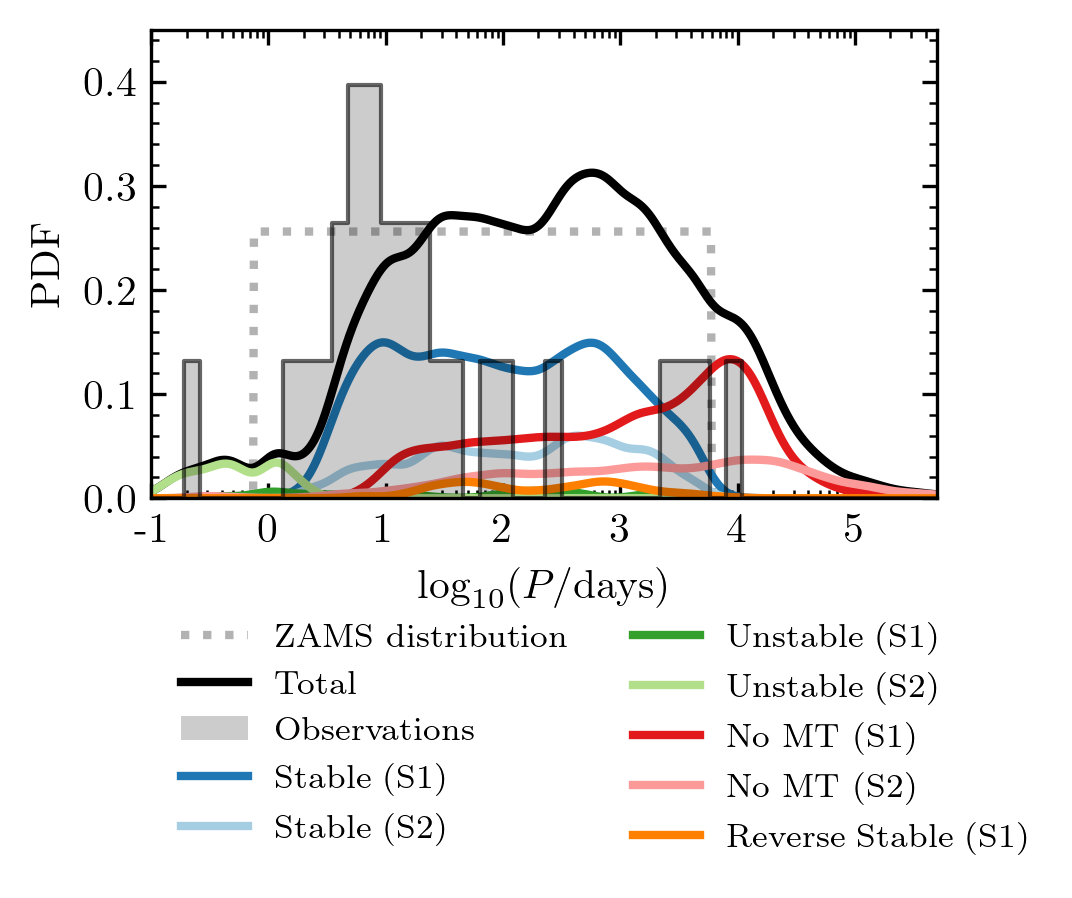

In [16]:
from posydon.popsyn.distributions import Sana12Period, PowerLawPeriod

weights = weight_array * model_weight_array

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

mask = binary_mask

MT_interactions = channel_masks


colours = CHANNEL_COLOURS


flatP = PDF_logP.pdf(10**x_eval)
ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
ax.plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

plot_observations(obs_df,
                  ax=ax)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])




# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)
    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_paths = str(FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

# rescaled observations by 0.5!!!

WNL: 0.14442052821763973


Stable (S1): 0.452


Stable (S2): 0.191
Unstable (S1): 0.008
Unstable (S2): 0.000


No MT (S1): 0.141


No MT (S2): 0.161
Reverse Stable (S1): 0.047


...

WC: 0.27740034083667986


Stable (S1): 0.293
Stable (S2): 0.076


Unstable (S1): 0.011
Unstable (S2): 0.041


No MT (S1): 0.388


No MT (S2): 0.171
Reverse Stable (S1): 0.019


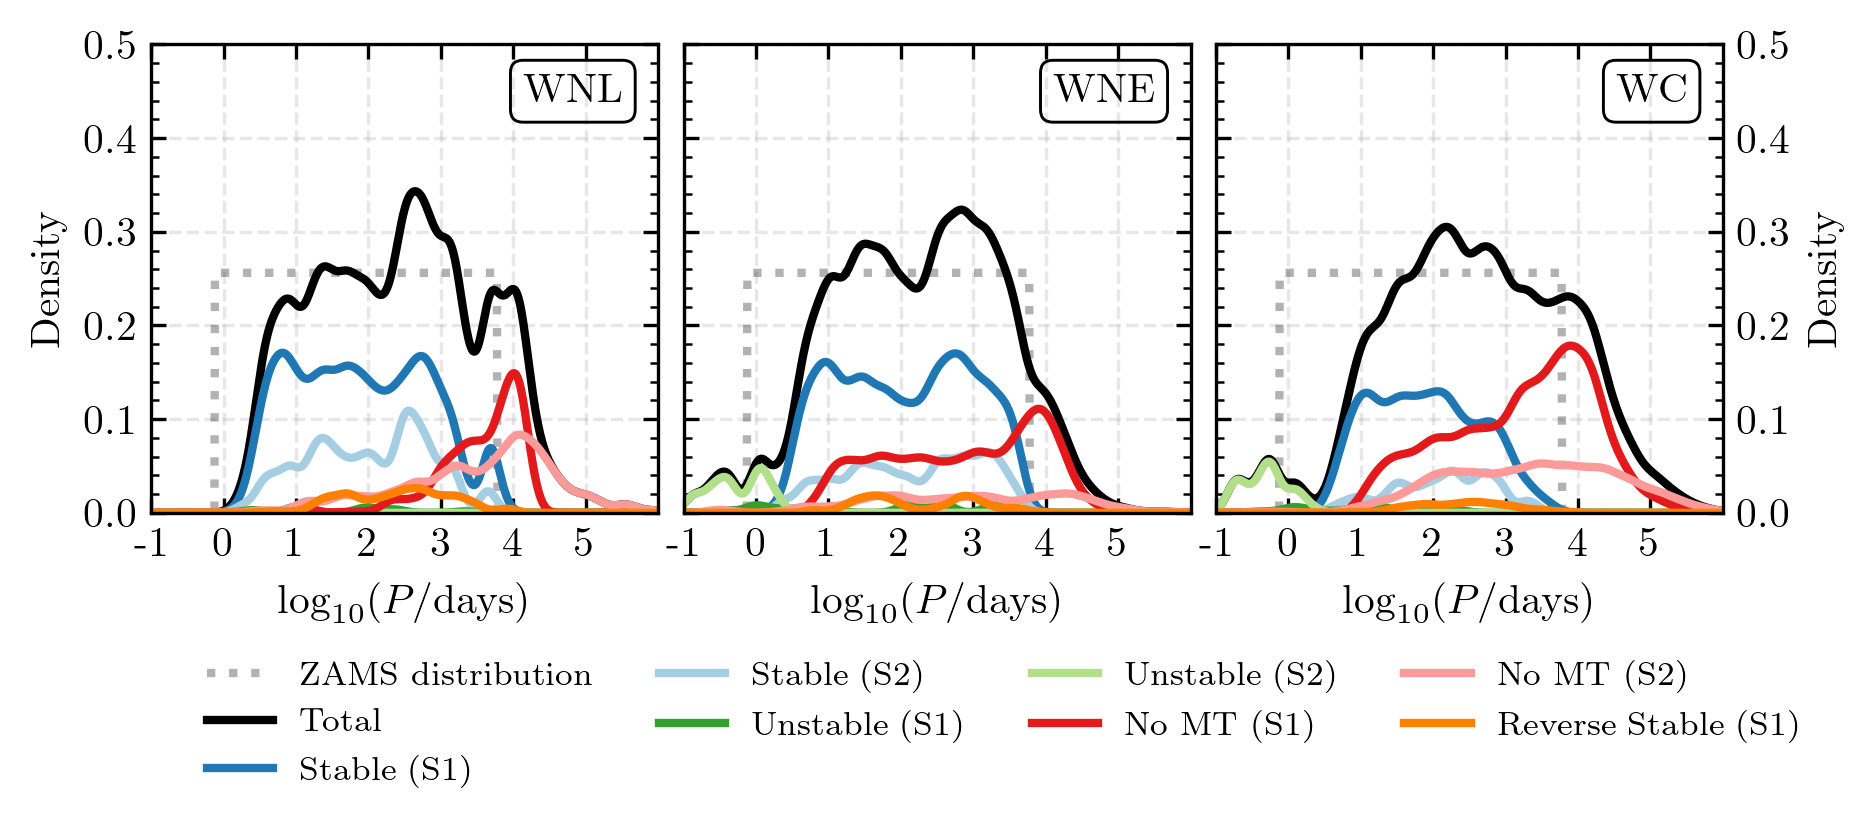

In [17]:
from posydon.popsyn.distributions import Sana12Period

fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

weights = weight_array * model_weight_array

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(-1, 7, 1000)


mask = binary_mask

MT_interactions = channel_masks


colours = CHANNEL_COLOURS


flatP = PDF_logP.pdf(10**x_eval)
for ax in axes:
    ax.plot(10**x_eval, flatP, ls=':',  color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')



# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & WNL]), weights=weights[mask & WNL], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & WNL].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNL & mt_mask]), weights=weights[mask & WNL & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNL & mt_mask]) / np.sum(weights[mask & WNL])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Plot WNE
kde = gaussian_kde(np.log10(period_array[mask & WNE]), weights=weights[mask & WNE], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WNE KDEs
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WNE:", weights[mask & WNE].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNE & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNE & mt_mask]), weights=weights[mask & WNE & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNE & mt_mask]) / np.sum(weights[mask & WNE])
    print(f"{label}: {fraction:.3f}")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# plot WC
kde = gaussian_kde(np.log10(period_array[mask & WC]), weights=weights[mask & WC], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WC KDEs
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WC:", weights[mask & WC].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WC & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WC & mt_mask]), weights=weights[mask & WC & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WC & mt_mask]) / np.sum(weights[mask & WC])
    print(f"{label}: {fraction:.3f}")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout

for ax in axes:
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.5)
    ax.grid(True, which='major', ls='--', alpha=0.3)
    

axes[0].set_ylabel('Density')
axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

axes[1].set_yticklabels([])
# move ytick label to right side for right plot
axes[-1].set_ylabel('Density')
axes[-1].yaxis.set_label_position("right")
axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

plt.subplots_adjust(wspace=0.05)

figure_paths = str(FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/MW_subtype_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_subtype_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

# Investigate specific models around 10^{2.5} days because they create some sort of peak.

In [18]:
mask = (period_array >10**(2.5)) & (period_array < 10**(3))

In [19]:
period_array[binary_mask & (WNL | WNE | WC) & mask & channel_masks['Stable (S1)']]

print(np.unique(key_array[binary_mask & (WNL | WNE | WC) & mask & channel_masks['Stable (S1)']]))

[   130    131    187 ... 299921 299959 299987]


state                                            detached
event                                                ZAMS
time                                                  0.0
orbital_period                                   3.866083
eccentricity                                          0.0
lg_mtransfer_rate                                     NaN
step_names                                   initial_cond
step_times                                            0.0
S1_state                            H-rich_Core_H_burning
S1_mass                                         16.718077
S1_log_R                                              0.0
S1_log_L                                              NaN
S1_lg_mdot                                            NaN
S1_he_core_mass                                       0.0
S1_he_core_radius                                     NaN
S1_co_core_mass                                       NaN
S1_co_core_radius                                     NaN
S1_center_h1  

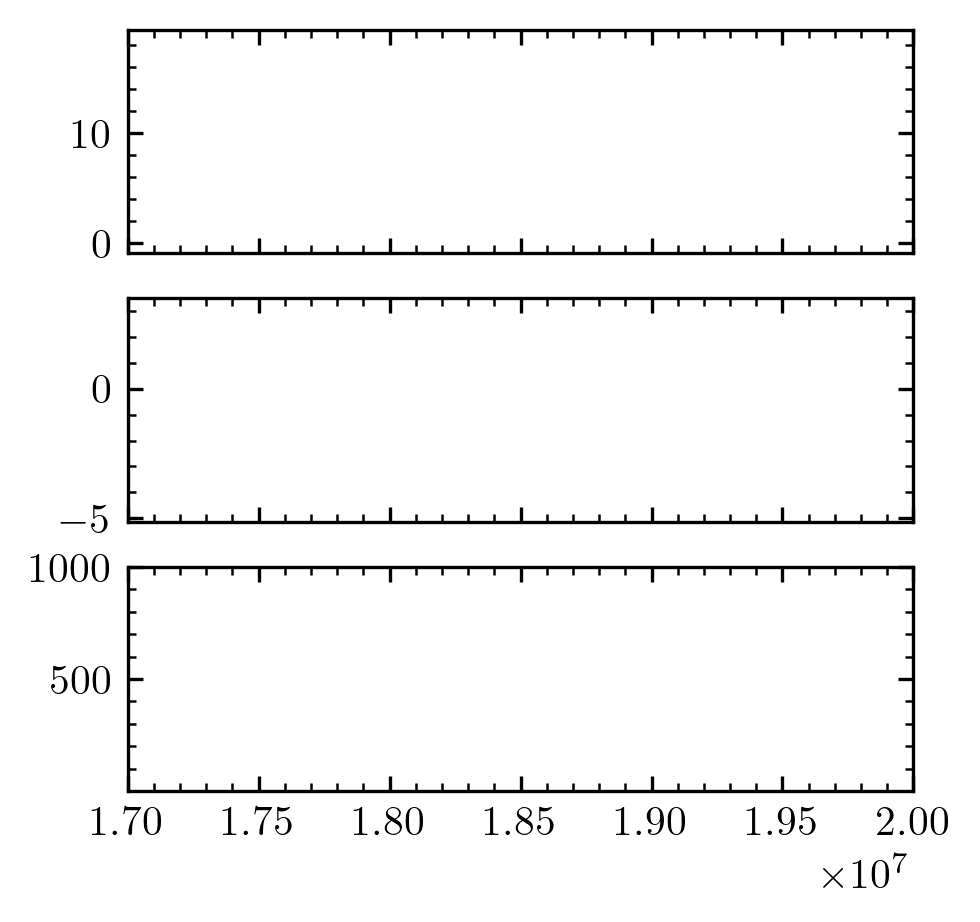

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(3.38, 2.535*1.3), sharex=True)
model = pop.history[8]

axes[0].plot(model['time'], model['S1_mass'], label='S1_mass')
axes[0].plot(model['time'], model['S2_mass'], label='S2_mass')
axes[0].plot(model['time'], model['S1_he_core_mass'], label='S1_he_core_mass')

axes[1].plot(model['time'], model['S1_log_R'], label='S1_log_R')
axes[1].plot(model['time'], model['S2_log_R'], label='S2_log_R')


axes[2].plot(model['time'], model['orbital_period'], label='orbital_period')
axes[2].set_ylim(1, 1000)
axes[0].set_xlim(1.7e7,2e7)

print(pop.history[8].iloc[0])
plt.show()

In [21]:
pop.history[8].iloc[60:90]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
8,merged,oMerging1,1.079125e+07,1.002248e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.384639,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.082434e+07,1.002313e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.382245,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.085743e+07,1.002378e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.379857,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.089052e+07,1.002443e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.377475,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.092361e+07,1.002508e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.375101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.095670e+07,1.002573e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.372734,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.098979e+07,1.002637e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.370375,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.102288e+07,1.002701e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.368025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.105597e+07,1.002765e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.365688,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
mt_hist = pop.oneline['mt_history_HMS_HMS'].iloc[:, 0]


# S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
# S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
# S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_reverse_MT')[0])
# S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# # S1 interaction masks - only apply to S1 entries
# S1_entries = (star_array == 'S1')
# channel_masks['Stable (S1)'] = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))


In [23]:
S1_entries = (star_array == 'S1')
S1_last_postMS_indices = set(mt_hist.index[mt_hist == 'Last stable RLOF during postMS'])

S1_mask_postMS = S1_entries & np.isin(key_array, np.array(list(S1_last_postMS_indices)))


Reverse Stable (S1): 0.339


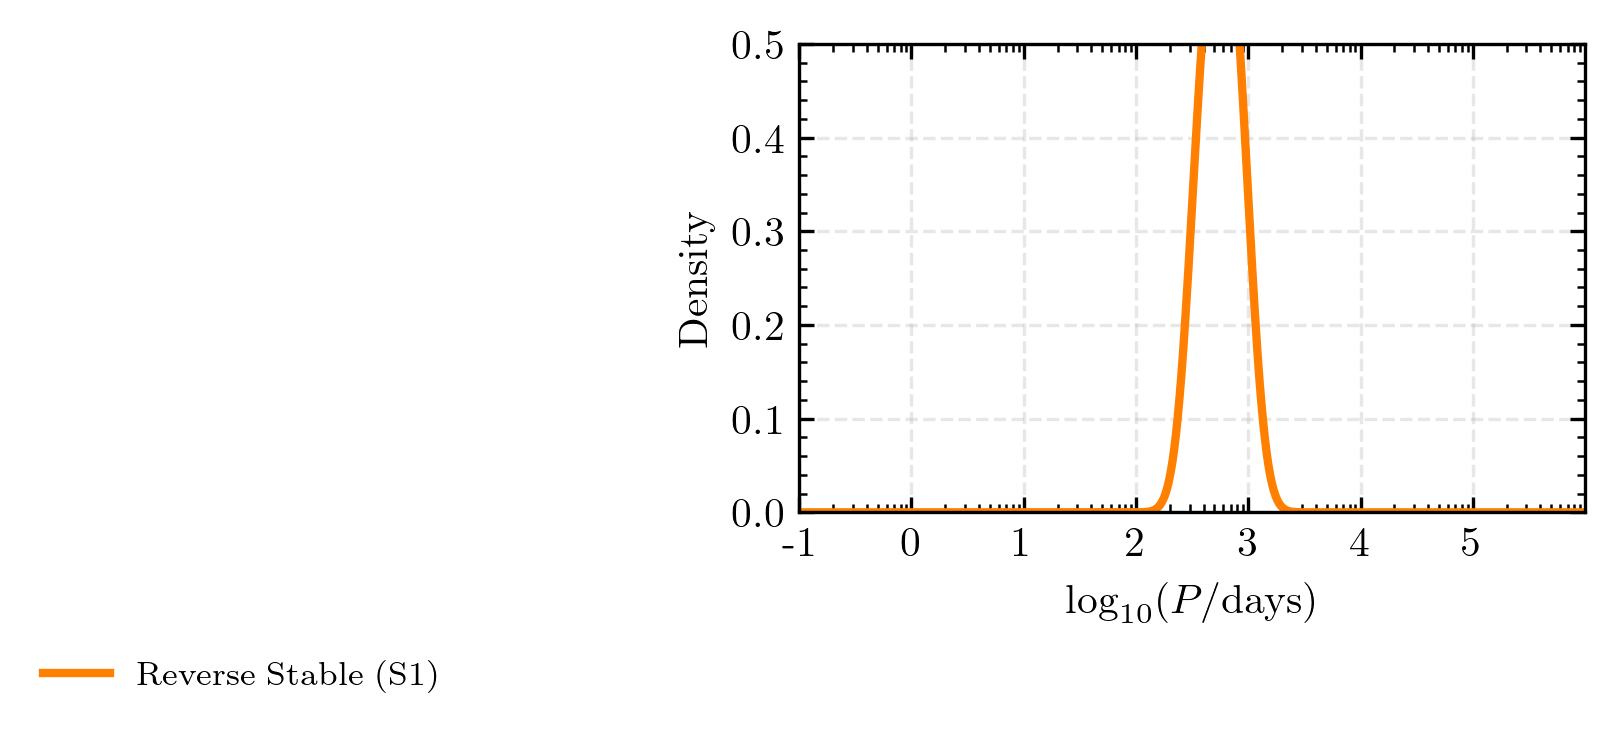

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

kde = gaussian_kde(np.log10(period_array[mask & WC & S1_mask_postMS]), weights=weights[mask & WC & S1_mask_postMS], bw_method=0.1)
kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
kde_eval = kde(x_eval)
fraction = np.sum(weights[mask & WC & S1_mask_postMS]) / np.sum(weights[mask & WC])
print(f"{label}: {fraction:.3f}")
ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 1e6)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.5)
ax.grid(True, which='major', ls='--', alpha=0.3)
    

ax.set_ylabel('Density')
ax.legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)





In [25]:
mt_hist.value_counts()

mt_history_HMS_HMS
Last stable RLOF during postMS              84231
Unstable contact phase                      53974
Unstable RLOF during postMS                 47379
no RLOF                                     17702
Last stable RLOF during stripped He star    15669
Unstable RLOF during MS                     10969
Stable reverse mass-transfer phase           2774
Unstable reverse mass-transfer phase         2334
Stable contact phase                         1460
Unstable RLOF during stripped He star        1216
Last stable RLOF during MS                    476
Name: count, dtype: int64

# Other investigations